### Step 1: Import Libraries and Load the Olivetti Faces Dataset

First, we import the necessary libraries. We use the Olivetti faces dataset from `scikit-learn` which contains 400 grayscale images of faces (64x64 pixels). We flatten each image from a 2D grid into a 1D vector of 4,096 dimensions so that we can apply standard matrix operations.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

# Load the dataset
faces_data = fetch_olivetti_faces(shuffle=True, random_state=42)
images = faces_data.images
n_samples, height, width = images.shape
X = faces_data.data

print(f"Dataset shape: {X.shape} ({n_samples} samples, each represented by a {X.shape[1]}-dimensional vector)")

Dataset shape: (400, 4096) (400 samples, each represented by a 4096-dimensional vector)


### Step 2: Compute PCA (Eigenfaces)

We project the high-dimensional data (4096 dimensions) into a lower-dimensional space using PCA. We extract the top 150 principal components. The principal components (eigenvectors of the covariance matrix) represent the directions of maximum variance. Reshaping these components back to 64x64 grids reveals the ghostly "Eigenfaces".

In [ ]:
n_components = 150
pca = PCA(n_components=n_components, whiten=True, random_state=42)
pca.fit(X)
eigenfaces = pca.components_.reshape((n_components, height, width))

### Step 3: Visualize the Mean Face and Top Eigenfaces

By plotting the mean face and the highest-variance components (the top Eigenfaces), we can visualize what features (like lighting, face shape, or eyes) each principal component represents.

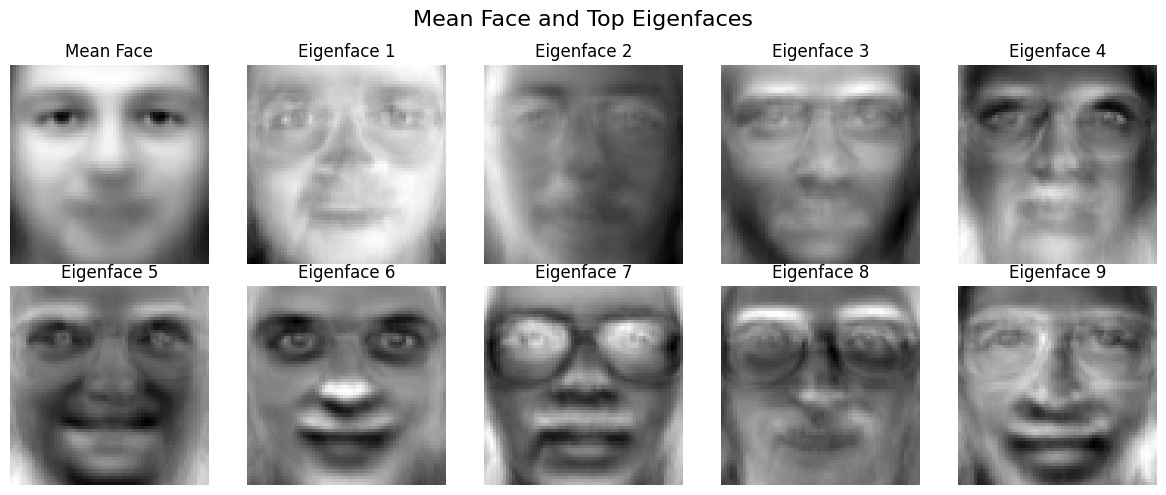

In [ ]:
plt.figure(figsize=(12, 5))

# Plot the mean face (the center of our face space)
plt.subplot(2, 5, 1)
plt.imshow(pca.mean_.reshape(height, width), cmap='gray')
plt.title("Mean Face")
plt.axis('off')

for i in range(9):
    plt.subplot(2, 5, i + 2)
    plt.imshow(eigenfaces[i], cmap='gray')
    plt.title(f"Eigenface {i+1}")
    plt.axis('off')

plt.suptitle("Mean Face and Top Eigenfaces", fontsize=16)
plt.tight_layout()
plt.show()

### Step 4: Exemplify Reconstruction with Varying Principal Components

Any face in the dataset can be approximated as a linear combination of the mean face and a subset of the Eigenfaces. Here, we observe how adding more principal components (increasing `k`) improves the reconstruction quality, starting from a blurry average outline to a sharp, recognizable image of the original face.

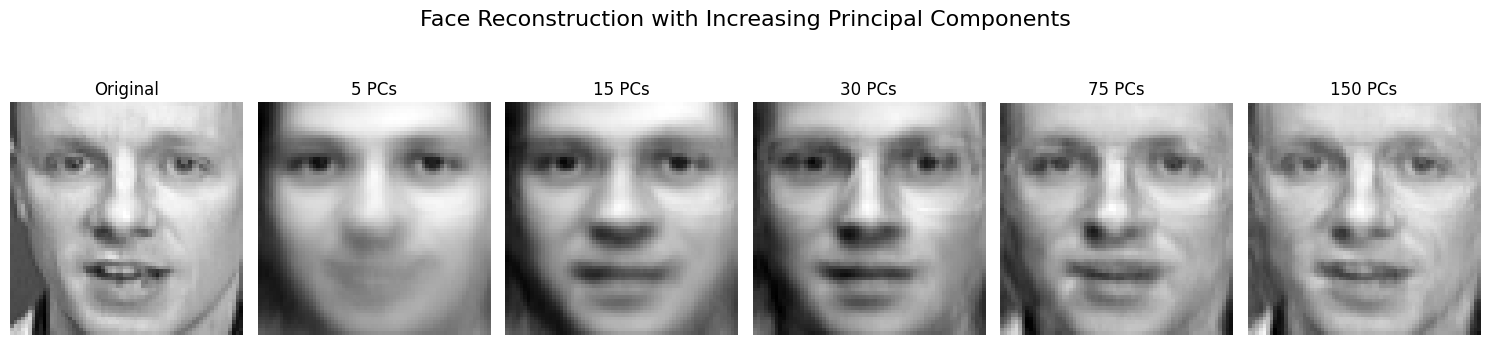

In [ ]:
target_face = X[0]
reconstructed_faces = []
component_steps = [5, 15, 30, 75, 150]

for k in component_steps:
    # Fit PCA and project using only the first k principal components
    pca_k = PCA(n_components=k, whiten=True, random_state=42)
    X_transformed = pca_k.fit_transform(X)
    X_reconstructed = pca_k.inverse_transform(X_transformed)
    reconstructed_faces.append(X_reconstructed[0].reshape(height, width))

# Plot the comparison of original vs reconstruction stages
plt.figure(figsize=(15, 4))
plt.subplot(1, len(component_steps) + 1, 1)
plt.imshow(target_face.reshape(height, width), cmap='gray')
plt.title("Original")
plt.axis('off')

for idx, k in enumerate(component_steps):
    plt.subplot(1, len(component_steps) + 1, idx + 2)
    plt.imshow(reconstructed_faces[idx], cmap='gray')
    plt.title(f"{k} PCs")
    plt.axis('off')

plt.suptitle("Face Reconstruction with Increasing Principal Components", fontsize=16)
plt.tight_layout()
plt.show()

### Step 5: Face Recognition using Eigenfaces

Now, we will use the projected PCA features to perform face recognition. We will:
1. Split the dataset into training and testing sets.
2. Fit PCA on the training set and project both the training and testing sets into the lower-dimensional PCA space.
3. Train a Support Vector Machine (SVM) classifier on these PCA features.
4. Evaluate the classifier's performance and visualize a few predictions.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Split into training and testing sets
y = faces_data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Fit PCA on training data and project both sets
n_components = 150
pca = PCA(n_components=n_components, whiten=True, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Train an SVM classifier
clf = SVC(kernel='rbf', class_weight='balanced', C=1000, gamma=0.005)
clf.fit(X_train_pca, y_train)

# Predict on the test set
y_pred = clf.predict(X_test_pca)

# Print evaluation metrics
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      0.33      0.50         3
           3       1.00      1.00      1.00         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
    

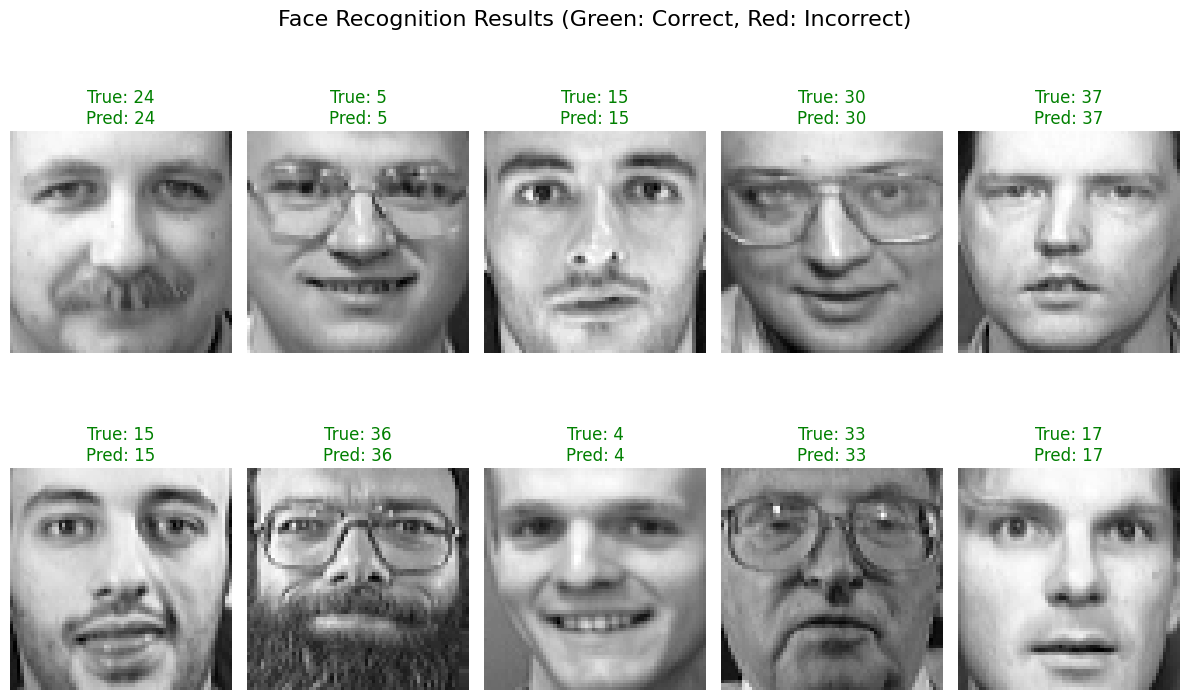

In [ ]:
# Visualize predictions with matching labels
plt.figure(figsize=(12, 8))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(64, 64), cmap='gray')
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    plt.title(f"True: {y_test[i]}\nPred: {y_pred[i]}", color=color)
    plt.axis('off')

plt.suptitle("Face Recognition Results (Green: Correct, Red: Incorrect)", fontsize=16)
plt.tight_layout()
plt.show()